# Simulated Annealing Schedules

Michael Hahsler

In [16]:
import numpy as np
import matplotlib.pyplot as plt

## Cooling Schedules

### Exponential Schedule

See [1].

In [17]:
def temperature_exponential(time, initial_temperature, alpha):
    return initial_temperature * alpha**time

### Linear Schedule

See [1].

In [18]:
def temperature_linear(time, initial_temperature, eta):
    return initial_temperature - eta * time

### Fast Simulated Annealing

See [3].

In [19]:
def temperature_fast(time, initial_temperature):
    return initial_temperature / (1 + time)

### Logarithmic (Classic) Cooling

If $T_0$ is greater than or equal to the largest energy barrier in the problem, this schedule is guaranteed to find the global optimum in the limit of infinite time [2]. The schedule is defined for $t > 0$.

In [20]:
def temperature_logarithmic(time, initial_temperature):
    return initial_temperature / np.log1p(time)

## Comparison

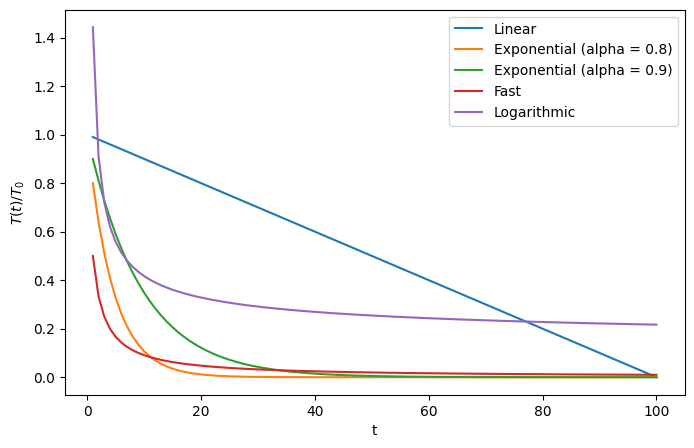

In [21]:
time = np.arange(1, 101)
initial_temperature = 1

schedules = {
    "Linear": temperature_linear(time, initial_temperature, eta=0.01),
    "Exponential (alpha = 0.8)": temperature_exponential(
        time, initial_temperature, alpha=0.8
    ),
    "Exponential (alpha = 0.9)": temperature_exponential(
        time, initial_temperature, alpha=0.9
    ),
    "Fast": temperature_fast(time, initial_temperature),
    "Logarithmic": temperature_logarithmic(time, initial_temperature),
}

plt.figure(figsize=(8, 5))
for name, temperature in schedules.items():
    plt.plot(time, temperature / initial_temperature, label=name)

plt.xlabel("t")
plt.ylabel(r"$T(t) / T_0$")
plt.legend()
plt.show()

## Literature

1. Kirkpatrick, S., Gelatt, C. D. Jr., and Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220, 671–680.
2. Hajek, B. (1988). Cooling schedules for optimal annealing. *Mathematics of Operations Research*, 13, 311–329.
3. Szu, H., and Hartley, R. (1987). Fast simulated annealing. *Physics Letters A*, 122(3–4), 157–162. [doi:10.1016/0375-9601(87)90796-1](https://doi.org/10.1016/0375-9601(87)90796-1)

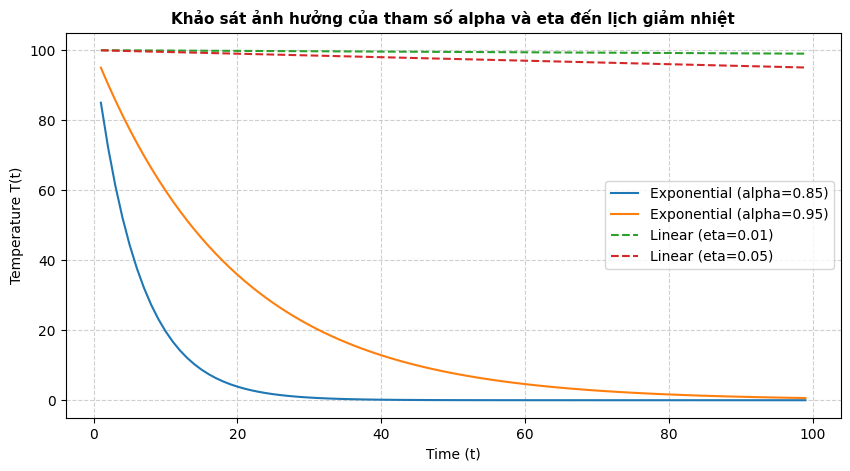

In [22]:
# Khảo sát sự thay đổi tham số alpha, eta và T0
time = np.arange(1, 100)
T0_list = [50, 100]
alpha_list = [0.85, 0.95]
eta_list = [0.01, 0.05]

plt.figure(figsize=(10, 5))

# Thử nghiệm thay đổi alpha cho lịch Exponential
for a in alpha_list:
    plt.plot(time, temperature_exponential(time, initial_temperature=100, alpha=a), label=f"Exponential (alpha={a})")

# Thử nghiệm thay đổi eta cho lịch Linear
for e in eta_list:
    plt.plot(time, temperature_linear(time, initial_temperature=100, eta=e), linestyle='--', label=f"Linear (eta={e})")

plt.title("Khảo sát ảnh hưởng của tham số alpha và eta đến lịch giảm nhiệt", fontsize=11, fontweight='bold')
plt.xlabel("Time (t)")
plt.ylabel("Temperature T(t)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## Nhận xét về ảnh hưởng của tham số $\alpha$, $\eta$ và $T_0$
- **Tham số $\alpha$ (Exponential Schedule):** Khi tăng $\alpha$ từ $0.85$ lên $0.95$ (hoặc sát $1$), đồ thị nhiệt độ suy giảm chậm và thoải hơn, giữ nhiệt độ ở mức cao trong nhiều vòng lặp hơn.
- **Tham số $\eta$ (Linear Schedule):** Định mức độ hạ nhiệt tuyến tính đều đặn. 
- **Kết luận lịch nhiệt nào chấp nhận bước xấu lâu hơn:** Lịch **Exponential với $\alpha$ lớn** là lịch duy trì nhiệt độ cao lâu nhất ở giai đoạn đầu. Do xác suất chấp nhận bước đi tồi hơn là $p = \exp(-\Delta / T)$, nhiệt độ cao giúp thuật toán **chấp nhận các bước đi tăng xung đột $f$ tạm thời trong nhiều vòng lặp hơn**, qua đó tăng cường khả năng khám phá không gian tìm kiếm và thoát khỏi bẫy cực trị cục bộ (local optimum) hiệu quả hơn hẳn các lịch làm nguội nhanh.

In [23]:
import time
import random

# Hàm đếm xung đột cho bài toán n-Queens
def conflicts(board):
    n = len(board)
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    return sum(n * (n - 1) // 2 for n in horizontal_cnt + diagonal1_cnt + diagonal2_cnt)

# Hàm Simulated Annealing sử dụng lịch nhiệt truyền vào
def sa_with_schedule(n, schedule_func, initial_temp=50.0, max_iter=5000, **kwargs):
    current = np.random.randint(0, n, size=n)
    current_score = conflicts(current)
    best_score = current_score
    evals = 1
    
    start_time = time.time()
    for t in range(1, max_iter + 1):
        if current_score == 0:
            break
        temp = schedule_func(t, initial_temp, **kwargs)
        if temp <= 0: temp = 1e-5
        
        col, row = random.randint(0, n - 1), random.randint(0, n - 1)
        while row == current[col]:
            row = random.randint(0, n - 1)
            
        neighbor = np.copy(current)
        neighbor[col] = row
        score = conflicts(neighbor)
        evals += 1
        
        delta = score - current_score
        if delta < 0 or random.random() < np.exp(-delta / temp):
            current = neighbor
            current_score = score
            if current_score < best_score:
                best_score = current_score
                
    runtime = (time.time() - start_time) * 1000
    return best_score, evals, runtime

# Chạy thử nghiệm đối chiếu 2 lịch nhiệt (Exponential và Fast) trên n = 8
n = 8
print(f"--- ĐỐI CHƯỚC THỰC NGHIỆM TRÊN n-Queens (n = {n}) ---")

score_exp, evals_exp, time_exp = sa_with_schedule(n, temperature_exponential, alpha=0.95)
print(f"[Exponential alpha=0.95] -> Số xung đột f: {score_exp} | Số lần gọi conflicts(): {evals_exp} | Thời gian: {time_exp:.2f} ms")

score_fast, evals_fast, time_fast = sa_with_schedule(n, temperature_fast)
print(f"[Fast Schedule]         -> Số xung đột f: {score_fast} | Số lần gọi conflicts(): {evals_fast} | Thời gian: {time_fast:.2f} ms")

--- ĐỐI CHƯỚC THỰC NGHIỆM TRÊN n-Queens (n = 8) ---
[Exponential alpha=0.95] -> Số xung đột f: 0 | Số lần gọi conflicts(): 198 | Thời gian: 1.56 ms
[Fast Schedule]         -> Số xung đột f: 0 | Số lần gọi conflicts(): 466 | Thời gian: 3.67 ms


## Đánh giá thực nghiệm giữa lịch Mũ (Exponential) và lịch Nhanh (Fast Schedule) trên n-Queens (n = 8)

Qua kết quả chạy thử nghiệm thực tế, mình rút ra một số nhận xét sau:

- **Chất lượng nghiệm:** Cả hai lịch nhiệt đều tìm được bàn cờ tối ưu với số xung đột $f = 0$. Chứng tỏ thuật toán đều có khả năng giải quyết tốt bài toán ở kích thước $n=8$.
- **Hiệu suất & Số vòng lặp:** 
  - **Lịch Mũ ($\alpha = 0.95$):** Tối ưu hơn hẳn khi chỉ cần gọi hàm `conflicts()` **198 lần** và chạy hết **1.56 ms**.
  - **Lịch Nhanh (Fast Schedule):** Tốn tới **466 lần** gọi hàm và mất **3.67 ms** (gấp hơn đôi so với lịch mũ). 
- **Nguyên nhân:** Lịch Fast giảm nhiệt độ nhanh quá ở giai đoạn đầu, khiến thuật toán đôi khi bị lướt qua các hướng đi ngon ăn, dẫn đến việc phải mất thêm nhiều bước lặp dao động mò mẫm hơn trước khi về đích.

**Kết luận:** Trong bài toán này, dùng lịch giảm nhiệt Mũ (Exponential) vừa tiết kiệm được thời gian chạy vừa giảm đáng kể số lần tính toán hàm mục tiêu, giúp thuật toán hội tụ mượt mà hơn.